# Lab 5 of 8 — Unsupervised learning II: anomaly detection and limited labels

*Learn when labels are absent, rare, or expensive.*

**Coverage.** Chapter 18; self-training and active learning are previewed from Chapter 19.

**Goal.** Evaluate anomaly rankings with held-back labels; compare self-training and active learning under limited labels.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier


def find_data_dir(name="all_datasets", marker="credit_card_fraud_dataset.csv"):
    """Search the script/working folder and their parents for a data folder holding `marker`."""
    starts = [Path.cwd()]
    try:
        starts.insert(0, Path(__file__).resolve().parent)  # not defined inside a notebook
    except NameError:
        pass
    for start in starts:
        for folder in [start, *start.parents]:
            if (folder / name / marker).is_file():
                return folder / name
    raise FileNotFoundError(f"Could not find {name}/{marker} above {starts}")


# The PDF's `PROJECT_ROOT = Path.cwd().parent` only works for notebooks directly in all_experiments/;
# this finds the same project root from inside "ML Lab 5/".
DATA = find_data_dir()
PROJECT_ROOT = DATA.parent

## Part A — Isolation Forest fraud ranking

Fit Isolation Forest **without** `is_fraud` on 10,000 transactions with about 1.5% fraud. Short isolation paths score as unusual; held-back labels evaluate the ranking.

In [2]:
fraud = pd.read_csv(DATA / "credit_card_fraud_dataset.csv")
print(fraud.head())

feature_cols = [
    "amount", "transaction_hour", "foreign_transaction", "location_mismatch",
    "device_trust_score", "velocity_last_24h", "cardholder_age",
]
X = fraud[feature_cols]
y = fraud["is_fraud"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

forest = IsolationForest(n_estimators=300, contamination="auto", random_state=42, n_jobs=-1)
forest.fit(X_train)  # no labels passed
anomaly_score = -forest.decision_function(X_test)  # higher = more unusual

   transaction_id  amount  transaction_hour merchant_category  \
0               1   84.47                22       Electronics   
1               2  541.82                 3            Travel   
2               3  237.01                17           Grocery   
3               4  164.33                 4           Grocery   
4               5   30.53                15              Food   

   foreign_transaction  location_mismatch  device_trust_score  \
0                    0                  0                  66   
1                    1                  0                  87   
2                    0                  0                  49   
3                    0                  1                  72   
4                    0                  0                  79   

   velocity_last_24h  cardholder_age  is_fraud  
0                  3              40         0  
1                  1              64         0  
2                  1              61         0  
3                  3  

Report ROC AUC, average precision, and operational precision among the top 100 alerts.

In [3]:
prevalence = y_test.mean()
ap = average_precision_score(y_test, anomaly_score)
print("fraud prevalence:", round(prevalence, 4))
print("ROC AUC:", round(roc_auc_score(y_test, anomaly_score), 4))
print("average precision:", round(ap, 4), " (", round(ap / prevalence, 1), "x prevalence)")

ranked = X_test.copy()
ranked["fraud_label"] = y_test.to_numpy()
ranked["anomaly_score"] = anomaly_score
ranked = ranked.sort_values("anomaly_score", ascending=False)

review_budget = 100
top_k_precision = ranked.head(review_budget)["fraud_label"].mean()
print(f"fraud found in the top {review_budget}: {top_k_precision:.0%}")
print(ranked[["fraud_label", "anomaly_score", "amount"]].head(10))

fraud prevalence: 0.015
ROC AUC: 0.9518
average precision: 0.2249  ( 15.0 x prevalence)
fraud found in the top 100: 20%
      fraud_label  anomaly_score  amount
6394            0       0.212892  840.89
5883            0       0.168657  978.56
1623            1       0.166446  569.02
522             0       0.165520  630.67
5536            1       0.163377   28.31
9073            0       0.158442  131.05
4642            0       0.155478  351.99
645             1       0.155063  398.17
7166            0       0.154388  353.58
7698            0       0.152780   75.88


Plot score overlap and precision versus review budget.

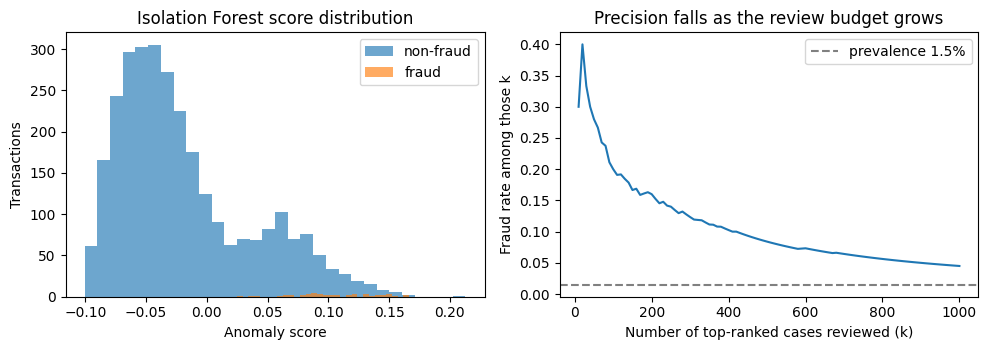

In [4]:
hits = ranked["fraud_label"].to_numpy()
k_values = np.arange(10, 1001, 10)
precision_at_k = [hits[:k].mean() for k in k_values]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(anomaly_score[y_test.to_numpy() == 0], bins=30, alpha=0.65, label="non-fraud")
axes[0].hist(anomaly_score[y_test.to_numpy() == 1], bins=30, alpha=0.65, label="fraud")
axes[0].set_xlabel("Anomaly score")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Isolation Forest score distribution")
axes[0].legend()

axes[1].plot(k_values, precision_at_k)
axes[1].axhline(prevalence, linestyle="--", color="grey", label=f"prevalence {prevalence:.1%}")
axes[1].set_xlabel("Number of top-ranked cases reviewed (k)")
axes[1].set_ylabel("Fraud rate among those k")
axes[1].set_title("Precision falls as the review budget grows")
axes[1].legend()
plt.tight_layout()
plt.show()

**Inspect.** ROC AUC is high (0.95), yet only 20% of the top 100 alerts are real fraud, because about 98.5% of transactions are non-fraud and a few of them score as the *most* unusual (the top-ranked row is a legitimate \$841 purchase). Average precision (0.22) is 15× the 1.5% prevalence, which is a useful lift but far from what AUC suggests. The score histograms overlap heavily in the upper tail, and the right-hand plot shows precision falling as the review budget grows. Quote precision at the real review budget, not AUC alone.

## Part B — Self-training and active learning with few labels

Split breast-cancer rows into a query pool, validation set, and sealed test set.

In [5]:
rng = np.random.default_rng(42)
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int).to_numpy()

X_dev, Xc_test, y_dev, yc_test = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)
X_pool, X_val, y_pool, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=7, stratify=y_dev
)
X_pool = X_pool.reset_index(drop=True)
y_pool = np.asarray(y_pool)
print("pool:", len(X_pool), " validation:", len(X_val), " test:", len(Xc_test))


def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000)),
    ])

pool: 319  validation: 107  test: 143


Hide 70% of pool labels as −1. Self-training adds predictions above confidence 0.90 and refits; erroneous pseudo-labels can reinforce mistakes.

In [6]:
y_partial = y_pool.copy()
y_partial[rng.random(len(y_partial)) < 0.70] = -1
print("labels kept:", int((y_partial != -1).sum()), "of", len(y_partial))

semi = Pipeline([
    ("scale", StandardScaler()),
    ("model", SelfTrainingClassifier(LogisticRegression(max_iter=2000), threshold=0.90)),
])
semi.fit(X_pool, y_partial)
print("self-training validation accuracy:",
      round(accuracy_score(y_val, semi.predict(X_val)), 3))

labels kept: 89 of 319
self-training validation accuracy: 0.963


Start both policies with 40 labels and add 15 per round. Compare queries nearest probability 0.5 with equal-budget random queries.

round 1: labels= 40 uncertainty=0.944 random=0.944
round 2: labels= 55 uncertainty=0.925 random=0.953
round 3: labels= 70 uncertainty=0.981 random=0.963


round 4: labels= 85 uncertainty=0.953 random=0.963
round 5: labels=100 uncertainty=0.953 random=0.953
round 6: labels=115 uncertainty=0.953 random=0.953
round 7: labels=130 uncertainty=0.953 random=0.963
round 8: labels=145 uncertainty=0.953 random=0.963


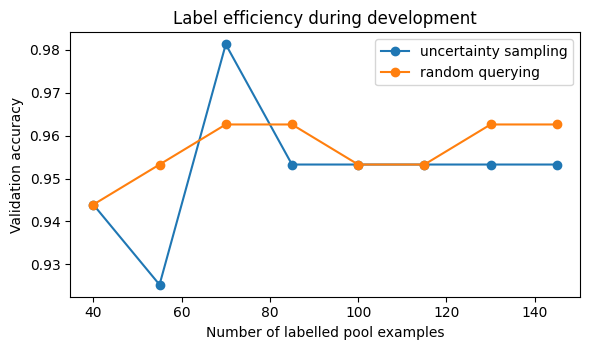

In [7]:
class0 = np.where(y_pool == 0)[0]
class1 = np.where(y_pool == 1)[0]
initial = np.concatenate([rng.choice(class0, 20, replace=False),
                          rng.choice(class1, 20, replace=False)])
active_labeled = set(initial.tolist())
random_labeled = set(initial.tolist())
rng_random = np.random.default_rng(123)
query_batch, rounds = 15, 8
label_counts, active_scores, random_scores = [], [], []

for round_no in range(rounds):
    active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
    active = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
    random_model = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])
    label_counts.append(len(active_labeled))
    active_scores.append(accuracy_score(y_val, active.predict(X_val)))
    random_scores.append(accuracy_score(y_val, random_model.predict(X_val)))
    print(f"round {round_no + 1}: labels={label_counts[-1]:3d} "
          f"uncertainty={active_scores[-1]:.3f} "
          f"random={random_scores[-1]:.3f}")
    if round_no == rounds - 1:
        break
    unlabeled = np.array([i for i in range(len(X_pool)) if i not in active_labeled])
    uncertainty = np.abs(active.predict_proba(X_pool.iloc[unlabeled])[:, 1] - 0.5)
    active_labeled.update(unlabeled[np.argsort(uncertainty)[:query_batch]].tolist())
    unlabeled = np.array([i for i in range(len(X_pool)) if i not in random_labeled])
    random_labeled.update(rng_random.choice(unlabeled, query_batch, replace=False).tolist())

plt.figure(figsize=(6, 3.6))
plt.plot(label_counts, active_scores, marker="o", label="uncertainty sampling")
plt.plot(label_counts, random_scores, marker="o", label="random querying")
plt.xlabel("Number of labelled pool examples")
plt.ylabel("Validation accuracy")
plt.title("Label efficiency during development")
plt.legend()
plt.tight_layout()
plt.show()

**Inspect.** Both curves flatten quickly, around 95% validation accuracy, with only about 40 labels. In this single run uncertainty sampling is not clearly better than random queries: it is ahead at one budget (70 labels) and behind at others, and the validation set has only 107 rows, so one example is about 0.9 percentage points. The sealed test set agrees (0.972 for both). Self-training with 89 kept labels reached 0.963 validation accuracy; confident pseudo-labels did not hurt here, but the lab gives no supervised-only baseline on those same 89 labels, so this run alone cannot show that they helped.

Both policies are finished, so the test set is opened once for each.

In [8]:
active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
active_final = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
random_final = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])
print("final test accuracy, uncertainty sampling:",
      round(accuracy_score(yc_test, active_final.predict(Xc_test)), 3))
print("final test accuracy, random querying:",
      round(accuracy_score(yc_test, random_final.predict(Xc_test)), 3))

final test accuracy, uncertainty sampling: 0.972
final test accuracy, random querying: 0.972


## Try it yourself

1. Compare fraud precision for review budgets 50 and 300.
2. Start with ten labels per class and reassess uncertainty sampling.

In [9]:
# 1. Fraud precision (and recall) at several review budgets, reusing the ranking above.
total_fraud = int(hits.sum())
for budget in (50, 100, 300):
    found = int(hits[:budget].sum())
    print(f"budget {budget:3d}: precision={found / budget:.0%}  "
          f"fraud caught={found}/{total_fraud} (recall {found / total_fraud:.0%})")

budget  50: precision=28%  fraud caught=14/45 (recall 31%)
budget 100: precision=20%  fraud caught=20/45 (recall 44%)
budget 300: precision=12%  fraud caught=37/45 (recall 82%)



20 labels per class at the start (mean of 20 runs)
  labels= 40  uncertainty=0.945  random=0.945  diff=+0.000
  labels= 55  uncertainty=0.957  random=0.950  diff=+0.007
  labels= 70  uncertainty=0.960  random=0.950  diff=+0.011
  labels= 85  uncertainty=0.958  random=0.950  diff=+0.008
  labels=100  uncertainty=0.958  random=0.949  diff=+0.009
  labels=115  uncertainty=0.957  random=0.950  diff=+0.006
  labels=130  uncertainty=0.956  random=0.951  diff=+0.005
  labels=145  uncertainty=0.957  random=0.951  diff=+0.006



10 labels per class at the start (mean of 20 runs)
  labels= 20  uncertainty=0.918  random=0.918  diff=+0.000
  labels= 35  uncertainty=0.945  random=0.936  diff=+0.009
  labels= 50  uncertainty=0.962  random=0.943  diff=+0.019
  labels= 65  uncertainty=0.957  random=0.944  diff=+0.014
  labels= 80  uncertainty=0.954  random=0.943  diff=+0.011
  labels= 95  uncertainty=0.954  random=0.950  diff=+0.004
  labels=110  uncertainty=0.954  random=0.951  diff=+0.003
  labels=125  uncertainty=0.954  random=0.954  diff=-0.000


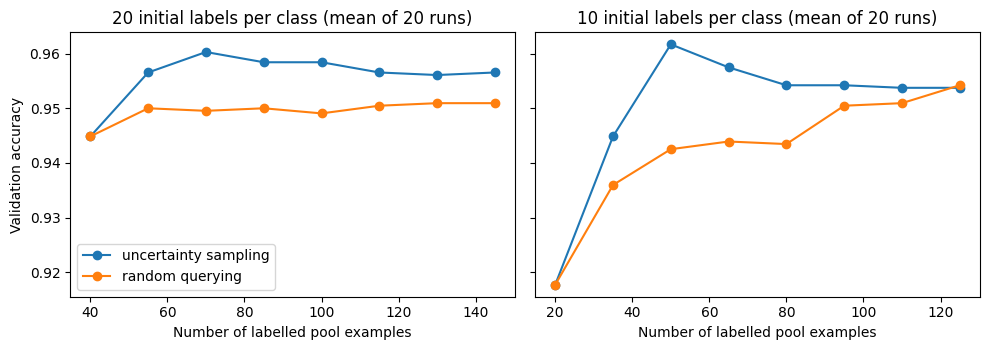

In [10]:
# 2. Restart with 10 labels per class. A single run is noisy on a small validation set,
#    so average over 20 different random starting labels.
def run_policies(per_class, seed):
    """Return (labels, uncertainty accuracy, random accuracy) curves for one seeded run."""
    gen = np.random.default_rng(seed)
    gen_random = np.random.default_rng(seed + 1000)
    start = np.concatenate([gen.choice(class0, per_class, replace=False),
                            gen.choice(class1, per_class, replace=False)])
    act, rnd = set(start.tolist()), set(start.tolist())
    counts, act_acc, rnd_acc = [], [], []
    for r in range(rounds):
        a_idx, r_idx = sorted(act), sorted(rnd)
        a_model = make_model().fit(X_pool.iloc[a_idx], y_pool[a_idx])
        r_model = make_model().fit(X_pool.iloc[r_idx], y_pool[r_idx])
        counts.append(len(act))
        act_acc.append(accuracy_score(y_val, a_model.predict(X_val)))
        rnd_acc.append(accuracy_score(y_val, r_model.predict(X_val)))
        if r == rounds - 1:
            break
        pool_a = np.array([i for i in range(len(X_pool)) if i not in act])
        unc = np.abs(a_model.predict_proba(X_pool.iloc[pool_a])[:, 1] - 0.5)
        act.update(pool_a[np.argsort(unc)[:query_batch]].tolist())
        pool_r = np.array([i for i in range(len(X_pool)) if i not in rnd])
        rnd.update(gen_random.choice(pool_r, query_batch, replace=False).tolist())
    return counts, act_acc, rnd_acc


n_repeats = 20
summary = {}
for per_class in (20, 10):
    runs = [run_policies(per_class, seed) for seed in range(n_repeats)]
    counts = runs[0][0]
    summary[per_class] = (
        counts,
        np.mean([r[1] for r in runs], axis=0),
        np.mean([r[2] for r in runs], axis=0),
    )
    print(f"\n{per_class} labels per class at the start (mean of {n_repeats} runs)")
    for c, a, r in zip(*summary[per_class]):
        print(f"  labels={c:3d}  uncertainty={a:.3f}  random={r:.3f}  diff={a - r:+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, per_class in zip(axes, (20, 10)):
    counts, a, r = summary[per_class]
    ax.plot(counts, a, marker="o", label="uncertainty sampling")
    ax.plot(counts, r, marker="o", label="random querying")
    ax.set_title(f"{per_class} initial labels per class (mean of {n_repeats} runs)")
    ax.set_xlabel("Number of labelled pool examples")
axes[0].set_ylabel("Validation accuracy")
axes[0].legend()
plt.tight_layout()
plt.show()

**Reflection.** **Budgets.** Widening the review budget trades precision for recall: reviewing 50 cases gives 28% precision but finds only 14 of 45 frauds (31%); 100 cases gives 20% / 44%; 300 cases gives 12% precision but catches 37 of 45 (82%). The right budget depends on the cost of a missed fraud versus a wasted review. These are counts from 45 fraud cases, so they are noisy.

**Ten labels per class.** Because one run is noisy, the comparison above averages 20 random starts (the policies share the same starting labels in each run). With 20 labels per class, uncertainty sampling is only about 0.5 to 1 point ahead of random. With 10 labels per class it helps more, up to about 2 points around 50 labels, which fits the idea that querying near the boundary matters most when labels are scarcest. The gap closes to about zero by 125 labels. These gaps are small relative to the validation set's resolution, so treat them as suggestive, not proven.

## Verification checklist

- The fraud labels are held back while the Isolation Forest is fitted, and used only to evaluate it.
- Precision at the actual review budget is reported alongside ROC AUC.
- Self-training and active learning are compared on the same fixed validation and test sets.
- Uncertainty sampling is compared with random queries at equal label budgets.